# Machine Learning: Energy Consumption Prediction

This notebook predicts household appliance energy use (`Appliances`, in Wh) using the UCI Appliances Energy Prediction dataset.

## 1. Load data

In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('../data/raw/energydata_complete.csv')
df.head()

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


## 2. Exploratory Data Analysis (EDA)

### 2.1 Dataset overview

In [30]:
print(df.shape)

(19735, 29)


In [31]:
print(df.dtypes)

date               str
Appliances       int64
lights           int64
T1             float64
RH_1           float64
T2             float64
RH_2           float64
T3             float64
RH_3           float64
T4             float64
RH_4           float64
T5             float64
RH_5           float64
T6             float64
RH_6           float64
T7             float64
RH_7           float64
T8             float64
RH_8           float64
T9             float64
RH_9           float64
T_out          float64
Press_mm_hg    float64
RH_out         float64
Windspeed      float64
Visibility     float64
Tdewpoint      float64
rv1            float64
rv2            float64
dtype: object


In [32]:
df.isna().sum().sum()

np.int64(0)

In [33]:
df.duplicated().sum()

np.int64(0)

In [34]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Appliances,19735.0,97.694958,102.524891,10.000000,50.000000,60.000000,100.000000,1080.000000
lights,19735.0,3.801875,7.935988,0.000000,0.000000,0.000000,0.000000,70.000000
T1,19735.0,21.686571,1.606066,16.790000,20.760000,21.600000,22.600000,26.260000
RH_1,19735.0,40.259739,3.979299,27.023333,37.333333,39.656667,43.066667,63.360000
T2,19735.0,20.341219,2.192974,16.100000,18.790000,20.000000,21.500000,29.856667
RH_2,19735.0,40.420420,4.069813,20.463333,37.900000,40.500000,43.260000,56.026667
T3,19735.0,22.267611,2.006111,17.200000,20.790000,22.100000,23.290000,29.236000
RH_3,19735.0,39.242500,3.254576,28.766667,36.900000,38.530000,41.760000,50.163333
T4,19735.0,20.855335,2.042884,15.100000,19.530000,20.666667,22.100000,26.200000
RH_4,19735.0,39.026904,4.341321,27.660000,35.530000,38.400000,42.156667,51.090000


**Observations:**
- The dataset has **19,735 rows and 29 columns**, recorded every 10 minutes from January to May 2016.
- There are **no missing values** and **no duplicate rows**.
- All columns are numeric except `date`, which is stored as text and must be converted to datetime.

In [35]:
df['date'] = pd.to_datetime(df['date'])

### 2.2 Target distribution

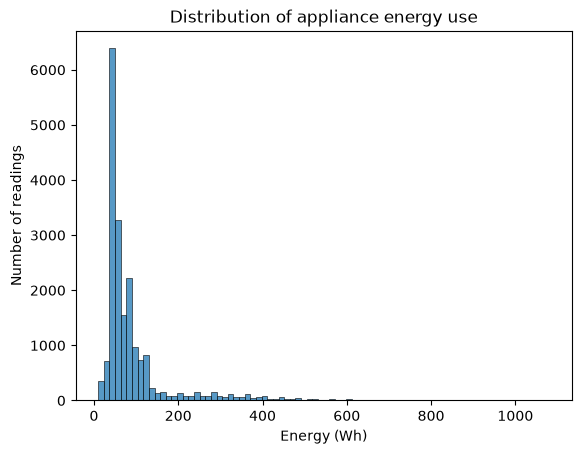

Skewness: 3.39


In [36]:
sns.histplot(df['Appliances'], bins=80)
plt.title('Distribution of appliance energy use')
plt.xlabel('Energy (Wh)'); plt.ylabel('Number of readings')
plt.show()

print('Skewness:', round(df['Appliances'].skew(), 2))

**Observations:**
- The target is **strongly right-skewed** (skewness = 3.39).
- The median is 60 Wh but the mean is 97.7 Wh. 95% of readings are 330 Wh or less, with a maximum of 1,080 Wh.
- Most of the time usage is low, with occasional large spikes. These spikes are likely genuine appliance use (cooking, washing), so they should not be removed automatically.

### 2.3 Energy use over time

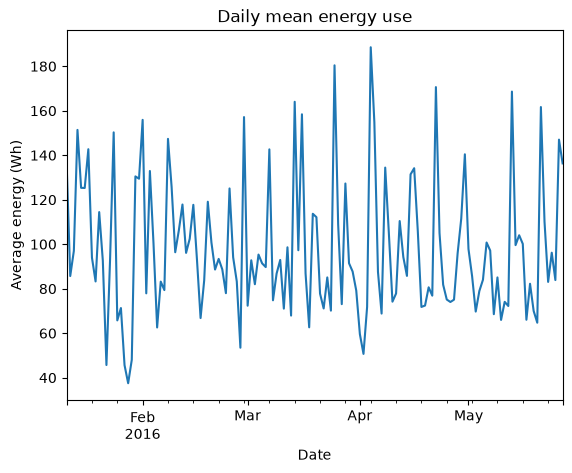

In [37]:
df.set_index('date')['Appliances'].resample('D').mean().plot(title='Daily mean energy use')
plt.xlabel('Date'); plt.ylabel('Average energy (Wh)')
plt.show()

**Observations:**
- Daily average energy use varies a lot from day to day (between about 38 and 189 Wh).
- The monthly average stays roughly constant (about 94–101 Wh), so there is no clear long-term trend.

### 2.4 Time patterns

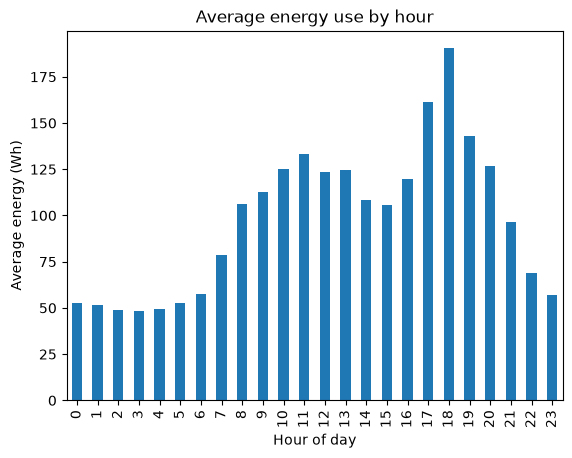

In [38]:
df.groupby(df['date'].dt.hour)['Appliances'].mean().plot(kind='bar', title='Average energy use by hour')
plt.xlabel('Hour of day'); plt.ylabel('Average energy (Wh)')
plt.show()

**Observations:**
- Energy use peaks at **18:00 (about 190 Wh)** and is lowest at **03:00 (about 48 Wh)**.
- The hour of the day has a strong effect, so `hour` will be a useful feature.

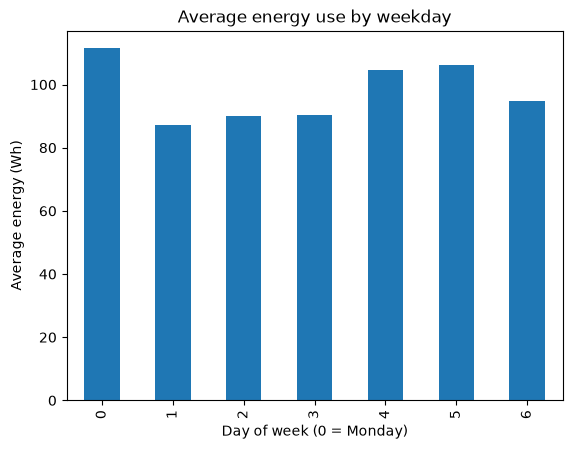

In [39]:
df.groupby(df['date'].dt.dayofweek)['Appliances'].mean().plot(kind='bar', title='Average energy use by weekday')
plt.xlabel('Day of week (0 = Monday)'); plt.ylabel('Average energy (Wh)')
plt.show()

**Observations:**
- Energy use is highest on Monday (111.5 Wh) and Friday/Saturday (about 105 Wh), and lowest on Tuesday (87 Wh).
- The weekday effect is smaller than the hour-of-day effect.

### 2.5 Temperature and humidity

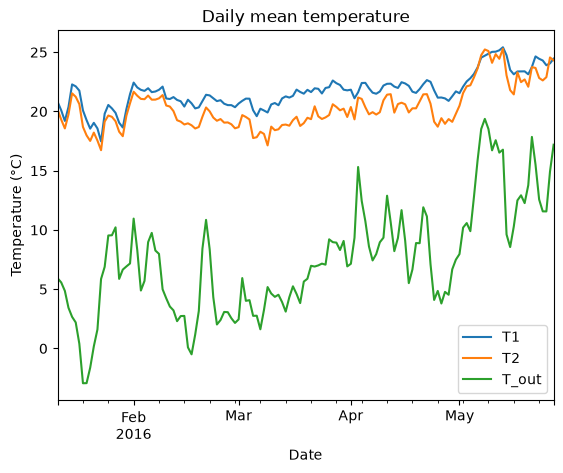

In [40]:
df.set_index('date')[['T1', 'T2', 'T_out']].resample('D').mean().plot(title='Daily mean temperature')
plt.xlabel('Date'); plt.ylabel('Temperature (°C)')
plt.show()

**Observations:**
- Indoor temperatures (T1, T2) stay within a narrow range of about 17–25 °C.
- Outdoor temperature (`T_out`) varies much more (about −3 to 19 °C) and rises from about 4 °C in January to about 14 °C in May.

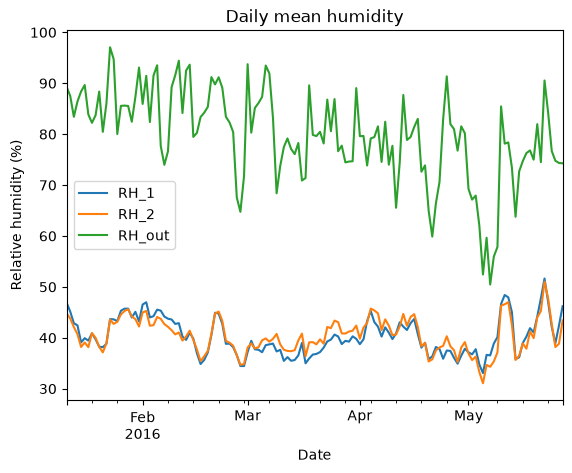

In [41]:
df.set_index('date')[['RH_1', 'RH_2', 'RH_out']].resample('D').mean().plot(title='Daily mean humidity')
plt.xlabel('Date'); plt.ylabel('Relative humidity (%)')
plt.show()

**Observations:**
- Indoor humidity stays around 31–52%.
- Outdoor humidity (`RH_out`) is higher and more variable (about 50–97%).

### 2.6 Correlations

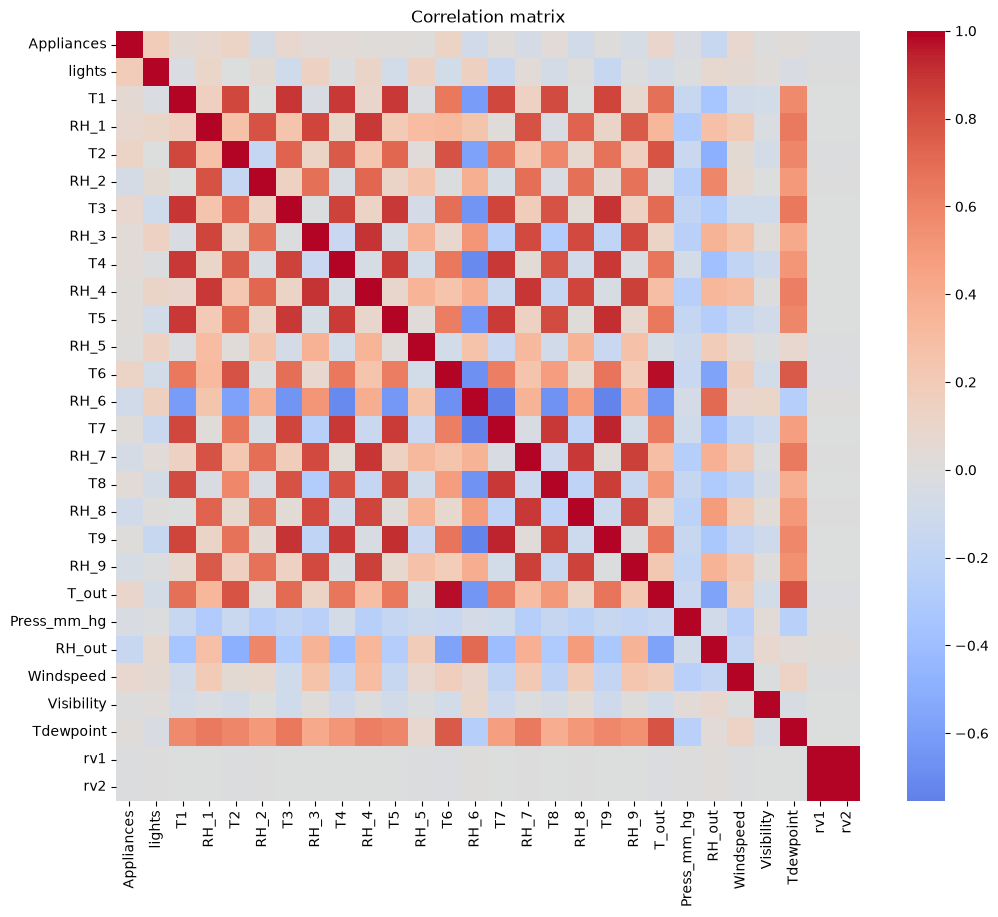

In [42]:
plt.figure(figsize=(12, 10))
sns.heatmap(df.drop(columns='date').corr(), cmap='coolwarm', center=0)
plt.title('Correlation matrix')
plt.show()

In [43]:
# Correlation of each feature with the target, strongest first
df.drop(columns='date').corr()['Appliances'].drop('Appliances').sort_values(key=abs, ascending=False)

lights         0.197278
RH_out        -0.152282
T2             0.120073
T6             0.117638
T_out          0.099155
RH_8          -0.094039
Windspeed      0.087122
RH_1           0.086031
T3             0.085060
RH_6          -0.083178
RH_2          -0.060465
RH_7          -0.055642
T1             0.055447
RH_9          -0.051462
T4             0.040281
T8             0.039572
RH_3           0.036292
Press_mm_hg   -0.034885
T7             0.025801
T5             0.019760
RH_4           0.016965
Tdewpoint      0.015353
rv2           -0.011145
rv1           -0.011145
T9             0.010010
RH_5           0.006955
Visibility     0.000230
Name: Appliances, dtype: float64

**Observations:**
- No feature has a strong linear correlation with energy use. The strongest are `lights` (0.20) and `RH_out` (−0.15).
- Many temperature variables are highly correlated with each other (e.g. `T6` and `T_out` = 0.975).
- `rv1` and `rv2` are random noise variables added by the dataset authors, so their correlation with the target is close to zero.

### EDA summary

- The data is clean: no missing values and no duplicate rows.
- The target is heavily skewed, so a log transform of the target may help the models.
- Time of day has a strong effect on energy use, so `hour` and `dayofweek` should be extracted as features.
- Individual features have weak linear relationships with energy use, which suggests that non-linear models (Random Forest, Gradient Boosting) should perform better than Linear Regression.
- `rv1` and `rv2` are random noise and will be dropped.

## Data Cleaning 

In [44]:
df = df.sort_values("date").reset_index(drop=True)

print("Duplicate timestamps:", df["date"].duplicated().sum())
print("Time gaps between readings:")
print(df["date"].diff().value_counts())

Duplicate timestamps: 0
Time gaps between readings:
date
0 days 00:10:00    19734
Name: count, dtype: int64


In [45]:
print("Negative energy:", (df["Appliances"] < 0).sum())
print("Negative lights:", (df["lights"] < 0).sum())
print("Humidity outside 0–100%:", ((df.filter(like="RH_") < 0) | (df.filter(like="RH_") > 100)).sum().sum())

Negative energy: 0
Negative lights: 0
Humidity outside 0–100%: 0


Upper limit: 175.0 Wh
High readings: 2138 (10.8%)


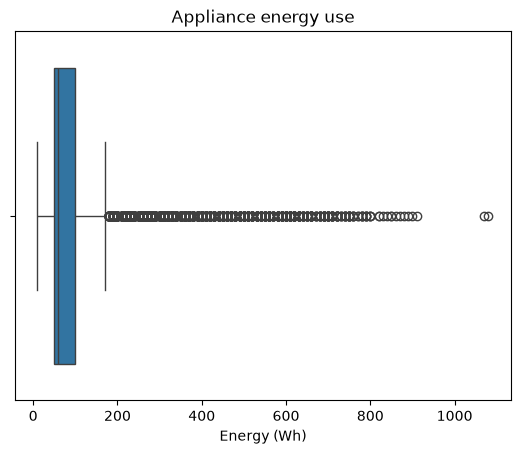

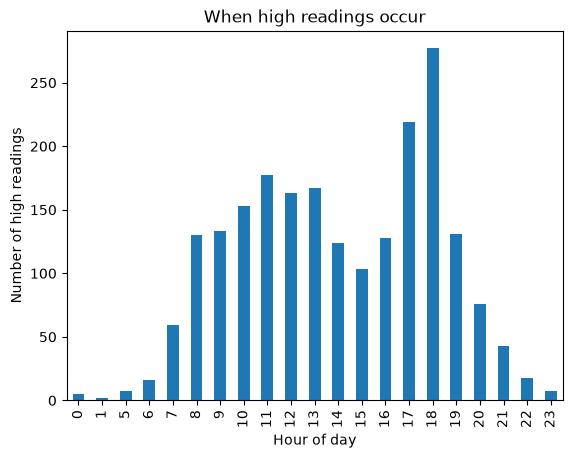

In [46]:
q1, q3 = df["Appliances"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
high = df[df["Appliances"] > upper]
print(f"Upper limit: {upper} Wh")
print(f"High readings: {len(high)} ({len(high) / len(df):.1%})")

sns.boxplot(x=df["Appliances"])
plt.title("Appliance energy use"); plt.xlabel("Energy (Wh)"); plt.show()

high["date"].dt.hour.value_counts().sort_index().plot(kind="bar", title="When high readings occur")
plt.xlabel("Hour of day"); plt.ylabel("Number of high readings"); plt.show()

In [47]:
df.to_csv("../data/processed/energy_clean.csv", index=False)
print("Saved:", df.shape)

Saved: (19735, 29)


## 4. Feature engineering

In [48]:
df["hour"] = df["date"].dt.hour
df["dayofweek"] = df["date"].dt.dayofweek          # 0 = Monday, 6 = Sunday
df["is_weekend"] = (df["dayofweek"] >= 5).astype(int)

df[["date", "hour", "dayofweek", "is_weekend"]].head()

,date,hour,dayofweek,is_weekend
0,2016-01-11 17:00:00,17,0,0
1,2016-01-11 17:10:00,17,0,0
2,2016-01-11 17:20:00,17,0,0
3,2016-01-11 17:30:00,17,0,0
4,2016-01-11 17:40:00,17,0,0


In [49]:
FEATURES = (
    ["lights"]
    + [f"T{i}" for i in range(1, 10)]
    + [f"RH_{i}" for i in range(1, 10)]
    + ["T_out", "Press_mm_hg", "RH_out", "Windspeed", "Visibility", "Tdewpoint"]
    + ["hour", "dayofweek", "is_weekend"]
)
TARGET = "Appliances"

X = df[FEATURES]
y = df[TARGET]

print("Number of features:", len(FEATURES))
print("X shape:", X.shape, " y shape:", y.shape)

Number of features: 28
X shape: (19735, 28)  y shape: (19735,)


In [50]:
df.groupby("is_weekend")["Appliances"].mean()

is_weekend
0     96.587674
1    100.581140
Name: Appliances, dtype: float64

## Train Validation & Split

In [51]:
n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train = df.iloc[:train_end]
val = df.iloc[train_end:val_end]
test = df.iloc[val_end:]

X_train, y_train = train[FEATURES], train[TARGET]
X_val, y_val = val[FEATURES], val[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

for name, part in [("Train", train), ("Validation", val), ("Test", test)]:
    print(f"{name:<11} {len(part):>6} rows  {part['date'].min()}  →  {part['date'].max()}")

Train        13814 rows  2016-01-11 17:00:00  →  2016-04-16 15:10:00
Validation    2960 rows  2016-04-16 15:20:00  →  2016-05-07 04:30:00
Test          2961 rows  2016-05-07 04:40:00  →  2016-05-27 18:00:00


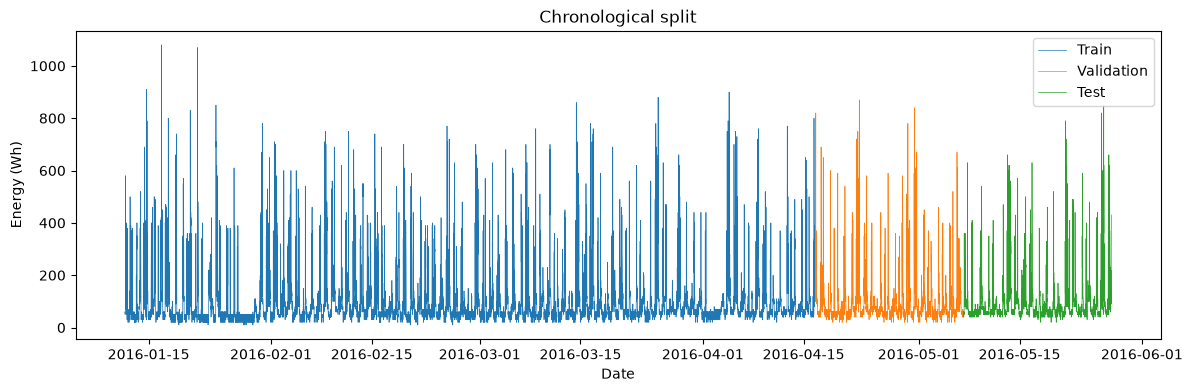

In [52]:
plt.figure(figsize=(14, 4))
plt.plot(train["date"], y_train, label="Train", linewidth=0.5)
plt.plot(val["date"], y_val, label="Validation", linewidth=0.5)
plt.plot(test["date"], y_test, label="Test", linewidth=0.5)
plt.title("Chronological split"); plt.xlabel("Date"); plt.ylabel("Energy (Wh)")
plt.legend(); plt.show()

In [53]:
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor 
def make_model(model):
    pipe = Pipeline([("scaler", StandardScaler()), ("model", model)])
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)

def evaluate(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
        "R2": r2_score(y_true, y_pred),
    }

In [57]:
model_classes = {
    "Linear Regression": LinearRegression,
    "Random Forest": RandomForestRegressor,
    "HistGradientBoosting": HistGradientBoostingRegressor,
    "XGBoost": XGBRegressor,
}

param_grids={
    "Linear Regression" : [{}],
    "Random Forest": [
        {"n_estimators": 200, "max_depth": d, "min_samples_leaf": leaf, "n_jobs": -1, "random_state": 42}
        for d in [8, 12, 16] for leaf in [5, 20]
    ],
    "HistGradientBoosting": [
        {"learning_rate": lr, "max_depth": d, "min_samples_leaf": leaf, "random_state": 42}
        for lr in [0.05, 0.1] for d in [4, 6] for leaf in [20, 50]
    ],
      "XGBoost": [
        {"n_estimators": 300, "learning_rate": lr, "max_depth": d, "min_child_weight": w,
         "subsample": 0.8, "colsample_bytree": 0.8, "n_jobs": -1, "random_state": 42}
        for lr in [0.05, 0.1] for d in [4, 6] for w in [5, 20]
    ],
}

In [58]:
results = []
best = {}

for name, grid in param_grids.items():
    for params in grid:
        model = make_model(model_classes[name](**params)).fit(X_train, y_train)
        scores = evaluate(y_val, model.predict(X_val))
        results.append({"model": name, **params, **scores})

        if name not in best or scores["MAE"] < best[name]["val"]["MAE"]:
            best[name] = {"model": model, "params": params, "val": scores}

    print(f"{name}: best validation MAE = {best[name]['val']['MAE']:.2f} Wh  {best[name]['params']}")


Linear Regression: best validation MAE = 42.08 Wh  {}
Random Forest: best validation MAE = 40.34 Wh  {'n_estimators': 200, 'max_depth': 12, 'min_samples_leaf': 20, 'n_jobs': -1, 'random_state': 42}
HistGradientBoosting: best validation MAE = 37.78 Wh  {'learning_rate': 0.05, 'max_depth': 4, 'min_samples_leaf': 50, 'random_state': 42}
XGBoost: best validation MAE = 38.54 Wh  {'n_estimators': 300, 'learning_rate': 0.05, 'max_depth': 4, 'min_child_weight': 20, 'subsample': 0.8, 'colsample_bytree': 0.8, 'n_jobs': -1, 'random_state': 42}


## 7 Model Evaluation 

In [59]:
rows = []
for name, b in best.items():
    m = b["model"]
    rows.append({"Model": name, "Split": "Train", **evaluate(y_train, m.predict(X_train))})
    rows.append({"Model": name, "Split": "Validation", **evaluate(y_val, m.predict(X_val))})

comparison = pd.DataFrame(rows).round(3)
comparison.pivot(index="Model", columns="Split", values=["MAE", "RMSE", "R2"])

MAE                RMSE                R2           
Split                  Train Validation    Train Validation  Train Validation
Model                                                                        
HistGradientBoosting  40.219     37.779   91.759     86.995  0.263      0.110
Linear Regression     46.959     42.077  100.407     85.152  0.117      0.148
Random Forest         35.147     40.336   82.368     85.961  0.406      0.132
XGBoost               35.227     38.541   80.940     86.513  0.426      0.120

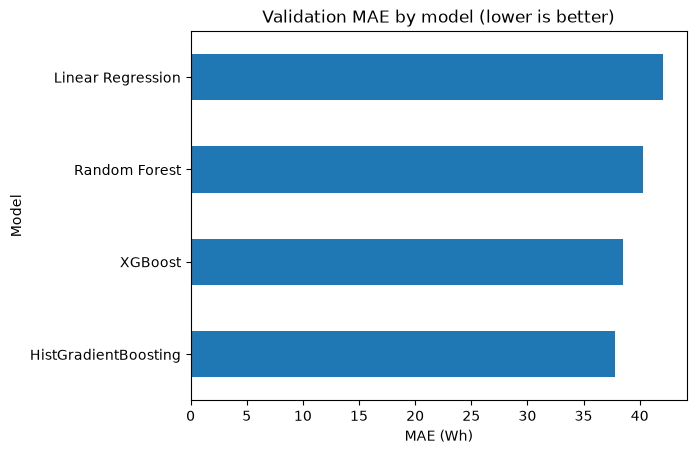

In [60]:
val_mae = comparison[comparison["Split"] == "Validation"].set_index("Model")["MAE"].sort_values()
val_mae.plot(kind="barh", title="Validation MAE by model (lower is better)")
plt.xlabel("MAE (Wh)"); plt.show()

In [ ]:
best_name = min(best, key=lambda k: best[k]["val"]["MAE"])
best_model = best[best_name]["model"]
print("Selected model:", best_name)
print("Settings:", best[best_name]["params"])

Selected model: HistGradientBoosting
Settings: {'learning_rate': 0.05, 'max_depth': 4, 'min_samples_leaf': 50, 'random_state': 42}


In [62]:
test_scores = evaluate(y_test, best_model.predict(X_test))
pd.Series(test_scores).round(3)

MAE     49.251
RMSE    84.601
R2       0.133
dtype: float64

## Overfit Check

In [63]:
gap = pd.DataFrame({
    "Train": evaluate(y_train, best_model.predict(X_train)),
    "Validation": evaluate(y_val, best_model.predict(X_val)),
    "Test": test_scores,
}).T.round(3)
gap

,MAE,RMSE,R2
Train,40.219,91.759,0.263
Validation,37.779,86.995,0.110
Test,49.251,84.601,0.133


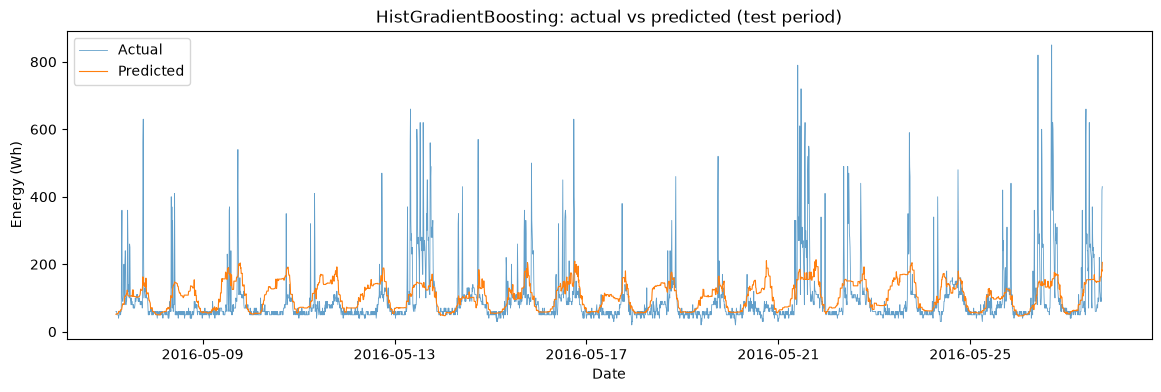

In [64]:
test_pred = best_model.predict(X_test)

plt.figure(figsize=(14, 4))
plt.plot(test["date"], y_test.values, label="Actual", linewidth=0.6, alpha=0.7)
plt.plot(test["date"], test_pred, label="Predicted", linewidth=0.8)
plt.title(f"{best_name}: actual vs predicted (test period)")
plt.xlabel("Date"); plt.ylabel("Energy (Wh)"); plt.legend(); plt.show()

In [65]:
errors = (y_test - test_pred).abs()
high = y_test > 175
print(f"MAE on normal readings (≤175 Wh): {errors[~high].mean():.1f} Wh")
print(f"MAE on high readings  (>175 Wh): {errors[high].mean():.1f} Wh")

MAE on normal readings (≤175 Wh): 33.9 Wh
MAE on high readings  (>175 Wh): 197.7 Wh


In [66]:
period_stats = pd.DataFrame({
    "Train": train[["T_out", "T1", "T2"]].mean(),
    "Validation": val[["T_out", "T1", "T2"]].mean(),
    "Test": test[["T_out", "T1", "T2"]].mean(),
}).round(1)
print(period_stats)

for col in ["T_out", "T1", "T2", "T6"]:
    pct = (test[col] > train[col].max()).mean()
    print(f"{col}: {pct:.1%} of test readings are hotter than any training reading")

       Train  Validation  Test
T_out    5.7         8.2  14.5
T1      21.1        22.0  24.2
T2      19.6        20.6  23.6
T_out: 15.4% of test readings are hotter than any training reading
T1: 55.1% of test readings are hotter than any training reading
T2: 26.4% of test readings are hotter than any training reading
T6: 23.2% of test readings are hotter than any training reading


## Save the final model

In [67]:
X_trainval = pd.concat([X_train, X_val])
y_trainval = pd.concat([y_train, y_val])

final_model = make_model(model_classes[best_name](**best[best_name]["params"]))
final_model.fit(X_trainval, y_trainval)

print("Final model trained on", len(X_trainval), "rows")

Final model trained on 16774 rows


In [68]:
import joblib
import sklearn
from pathlib import Path
from datetime import datetime

Path("../artifacts").mkdir(exist_ok=True)

bundle = {
    "pipeline": final_model,
    "features": FEATURES,
    "target": TARGET,
    "model_name": best_name,
    "params": best[best_name]["params"],
    "metrics": {
        "train": evaluate(y_train, best_model.predict(X_train)),
        "validation": best[best_name]["val"],
        "test": test_scores,
    },
    "feature_defaults": X_trainval.median().to_dict(),
    "feature_ranges": {c: [float(X_trainval[c].min()), float(X_trainval[c].max())] for c in FEATURES},
    "trained_on": "train + validation (2016-01-11 to 2016-05-07)",
    "sklearn_version": sklearn.__version__,
    "created_at": datetime.now().isoformat(timespec="seconds"),
}

joblib.dump(bundle, "../artifacts/energy_model.joblib")
print("Saved to artifacts/energy_model.joblib")


Saved to artifacts/energy_model.joblib


In [69]:
loaded = joblib.load("../artifacts/energy_model.joblib")

sample = X_test.iloc[[0]][loaded["features"]]
print("Model:", loaded["model_name"])
print("Number of features:", len(loaded["features"]))
print("Prediction for first test row:", round(float(loaded["pipeline"].predict(sample)[0]), 1), "Wh")
print("Actual value:", y_test.iloc[0], "Wh")

Model: HistGradientBoosting
Number of features: 28
Prediction for first test row: 54.1 Wh
Actual value: 60 Wh
